# Лабораторная работа 3. Полиномиальная регрессия методом наименьших квадратов

> Реализуйте программно восстановление функциональной зависимости методом наименьших
> квадратов с помощью полиномиальной регрессии. Для этого
>
> а) используйте значения параметра $M \in \{0, 1, \ldots, 15\}$;
>
> б) генерируйте выборку двумя способами: в первом случае моделируйте ошибку измерения как
> равномерно распределённую случайную величину, во втором — как нормально распределённую
> случайную величину;
>
> в) генерируйте значения $x$ из заданного интервала случайно в соответствии с равномерным
> распределением;
>
> г) в качестве распознаваемых функциональных зависимостей используйте следующие:
> $y = \cos x$, $y = 5x^3 + x^2 + 5$, $y = x \sin x$, $x \in [0, 2\pi]$.

## 1. Настройка окружения

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261003
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 2. МНК

По выборке $\{x^{(i)}, y^{(i)}\}_{i=1}^N$, $y^{(i)} = f(x^{(i)}) + \varepsilon^{(i)}$, ищем полином
$\tilde f(w, x) = w_0 + w_1 x + \ldots + w_M x^M$ (6), минимизирующий
$E(w) = \frac12 \sum_i \bigl(y^{(i)} - \tilde f(w, x^{(i)})\bigr)^2$ (2) (Задача 1, стр. 72; п. 4.3);
коэффициенты — решение системы (7): $\sum_j a_{ij} w_j = b_i$, $a_{ij} = \sum_k x_k^{i+j}$,
$b_i = \sum_k x_k^i y_k$. 

Перед построением системы $x$ проходит **Z-нормализацию**:
без неё элементы $a_{ij}$ при $M = 15$ различаются на ~30 порядков, и система решается с большой
погрешностью (проверка ниже). При $N < M + 1$ определитель системы равен нулю (задание 1), и
`lstsq` выбирает одно из бесконечного множества решений.

In [2]:
def normal_system(x, y, M):
    """Матрица A и вектор b системы (7)."""
    P = x[:, None] ** np.arange(M + 1)      # P[k, i] = x_k^i
    return P.T @ P, P.T @ y                 # a_ij = sum_k x_k^(i+j), b_i = sum_k x_k^i y_k

def fit(x, y, M):
    """Коэффициенты полинома степени M по выборке (x, y).

    Возвращает (w, mu, sd): коэффициенты для Z-нормализованного x и параметры нормализации.
    """
    mu, sd = x.mean(), x.std()
    A, b = normal_system((x - mu) / sd, y, M)
    w = np.linalg.lstsq(A, b, rcond=None)[0]
    return w, mu, sd

def predict(model, x):
    w, mu, sd = model
    return ((x - mu) / sd)[:, None] ** np.arange(len(w)) @ w

def E(model, x, y):
    """Функция ошибки (2)."""
    return 0.5 * np.sum((y - predict(model, x)) ** 2)

# Проверка: E(w) при решении системы (7) без нормализации и с ней
_rng = np.random.default_rng(1)
_x = _rng.uniform(0, 2 * np.pi, 200)
_y = _x * np.sin(_x) + _rng.normal(0, 0.5, 200)
for M in [3, 9, 15]:
    A, b = normal_system(_x, _y, M)
    w_raw = np.linalg.lstsq(A, b, rcond=None)[0]
    E_raw = 0.5 * np.sum((_y - (_x[:, None] ** np.arange(M + 1)) @ w_raw) ** 2)
    print(f"M = {M:2}: E(w) без нормализации = {E_raw:8.3f}, с Z-нормализацией = {E(fit(_x, _y, M), _x, _y):8.3f}")

M =  3: E(w) без нормализации =   64.960, с Z-нормализацией =   64.960
M =  9: E(w) без нормализации =   19.542, с Z-нормализацией =   19.444
M = 15: E(w) без нормализации =  104.565, с Z-нормализацией =   18.859


При росте $M$ минимум $E(w)$ может только уменьшаться: полиномы степени $M$ входят в полиномы
степени $M+1$. Рост $E(w)$ без нормализации означает, что система решена неверно.

## 3. Генерация выборки

$y = f(x) + \varepsilon$. Обе ошибки имеют нулевое среднее и одинаковое стандартное отклонение
$\sigma$, поэтому различается только закон распределения: $\mathcal N(0, \sigma^2)$ и
$\mathsf U[-\sigma\sqrt3, \sigma\sqrt3]$ (дисперсия $\mathsf U[-a, a]$ равна $a^2/3$).

Масштабы функций сильно различаются ($\cos x \in [-1, 1]$, а $5x^3 + x^2 + 5$ доходит до ~1290),
поэтому $\sigma$ берётся равным 20 % от стандартного отклонения значений функции на $[0, 2\pi]$.

In [3]:
FUNCS = {
    "cos x":          lambda x: np.cos(x),
    "5x^3 + x^2 + 5": lambda x: 5 * x**3 + x**2 + 5,
    "x sin x":        lambda x: x * np.sin(x),
}
NOISES = {"нормальная": "normal", "равномерная": "uniform"}
NOISE_LEVEL = 0.2
GRID = np.linspace(0, 2 * np.pi, 1000)
SIGMA = {name: NOISE_LEVEL * f(GRID).std() for name, f in FUNCS.items()}

def make_sample(func, n, noise, rng):
    x = rng.uniform(0, 2 * np.pi, n)
    s = SIGMA[func]
    eps = rng.normal(0, s, n) if noise == "normal" else rng.uniform(-s * np.sqrt(3), s * np.sqrt(3), n)
    return x, FUNCS[func](x) + eps

## 4. Восстановленные зависимости

Чёрная линия — $f(x)$, красная — полином степени $M$, точки — выборка.

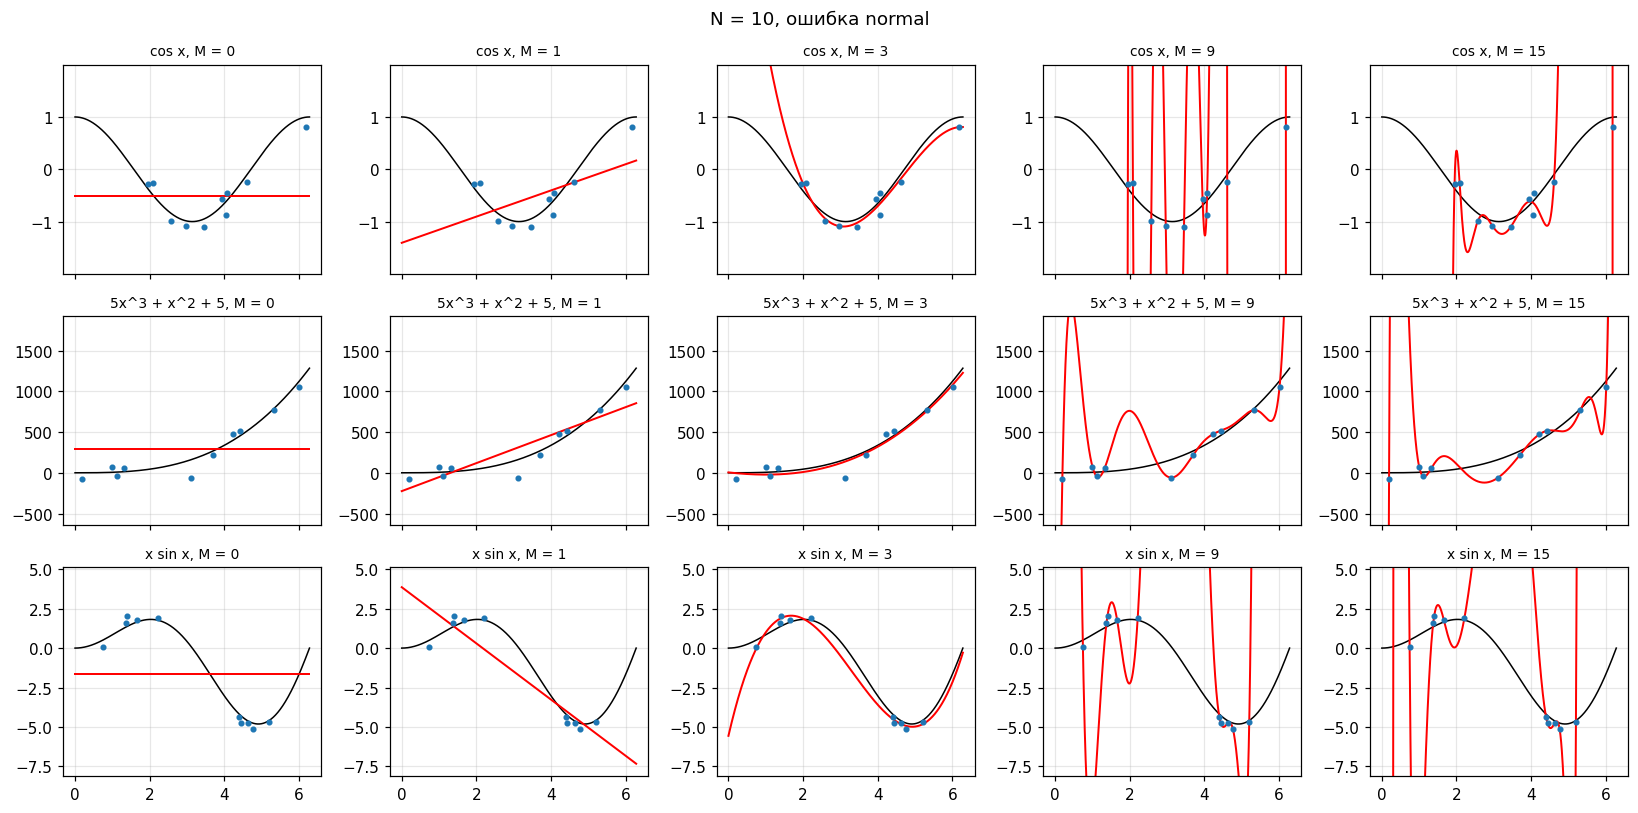

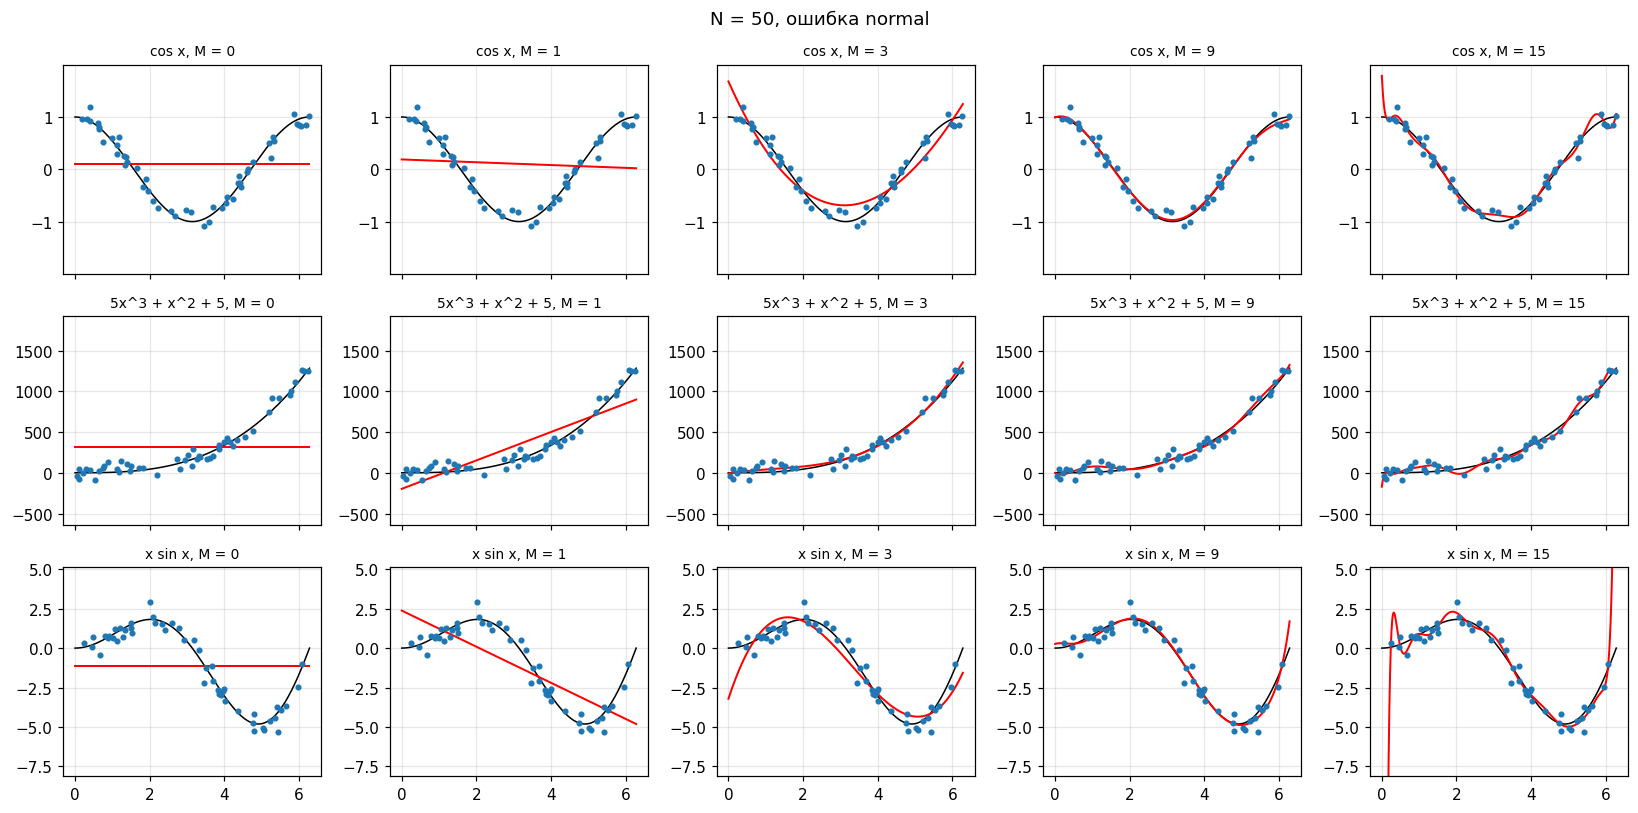

In [4]:
def plot_fits(n, noise="normal", Ms=(0, 1, 3, 9, 15)):
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(3, len(Ms), figsize=(3 * len(Ms), 7.5), sharex=True)
    for row, func in enumerate(FUNCS):
        x, y = make_sample(func, n, noise, rng)
        f = FUNCS[func](GRID)
        pad = 0.5 * (f.max() - f.min())
        for col, M in enumerate(Ms):
            ax = axes[row, col]
            ax.plot(GRID, f, "k", lw=1)
            ax.plot(GRID, predict(fit(x, y, M), GRID), "r", lw=1.3)
            ax.plot(x, y, "o", ms=3)
            ax.set_ylim(f.min() - pad, f.max() + pad)
            ax.set_title(f"{func}, M = {M}", fontsize=9)
    fig.suptitle(f"N = {n}, ошибка {noise}")
    plt.tight_layout()
    plt.show()

plot_fits(10)
plot_fits(50)

## 5. Ошибка в зависимости от $M$

Ошибку удобно сравнивать как среднеквадратичное отклонение $E_{RMS} = \sqrt{2E(w)/N}$: оно не
зависит от объёма выборки. Считаем его на обучающей выборке и на **контрольной** выборке из
1000 новых точек, делим на $\sigma$: значение 1 — уровень ошибки измерений.

In [5]:
N_VALUES = [10, 20, 50]
N_REPEATS = 100

rows = []
rng = np.random.default_rng(SEED)
for func in FUNCS:
    for noise_label, noise in NOISES.items():
        for n in N_VALUES:
            for _ in range(N_REPEATS):
                x, y = make_sample(func, n, noise, rng)
                x_test, y_test = make_sample(func, 1000, noise, rng)
                for M in range(16):
                    model = fit(x, y, M)
                    rows.append({"функция": func, "ошибка": noise_label, "N": n, "M": M,
                                 "train": np.sqrt(2 * E(model, x, y) / n) / SIGMA[func],
                                 "test": np.sqrt(2 * E(model, x_test, y_test) / 1000) / SIGMA[func]})

res = (pd.DataFrame(rows)
       .groupby(["функция", "ошибка", "N", "M"])[["train", "test"]].median()
       .reset_index())

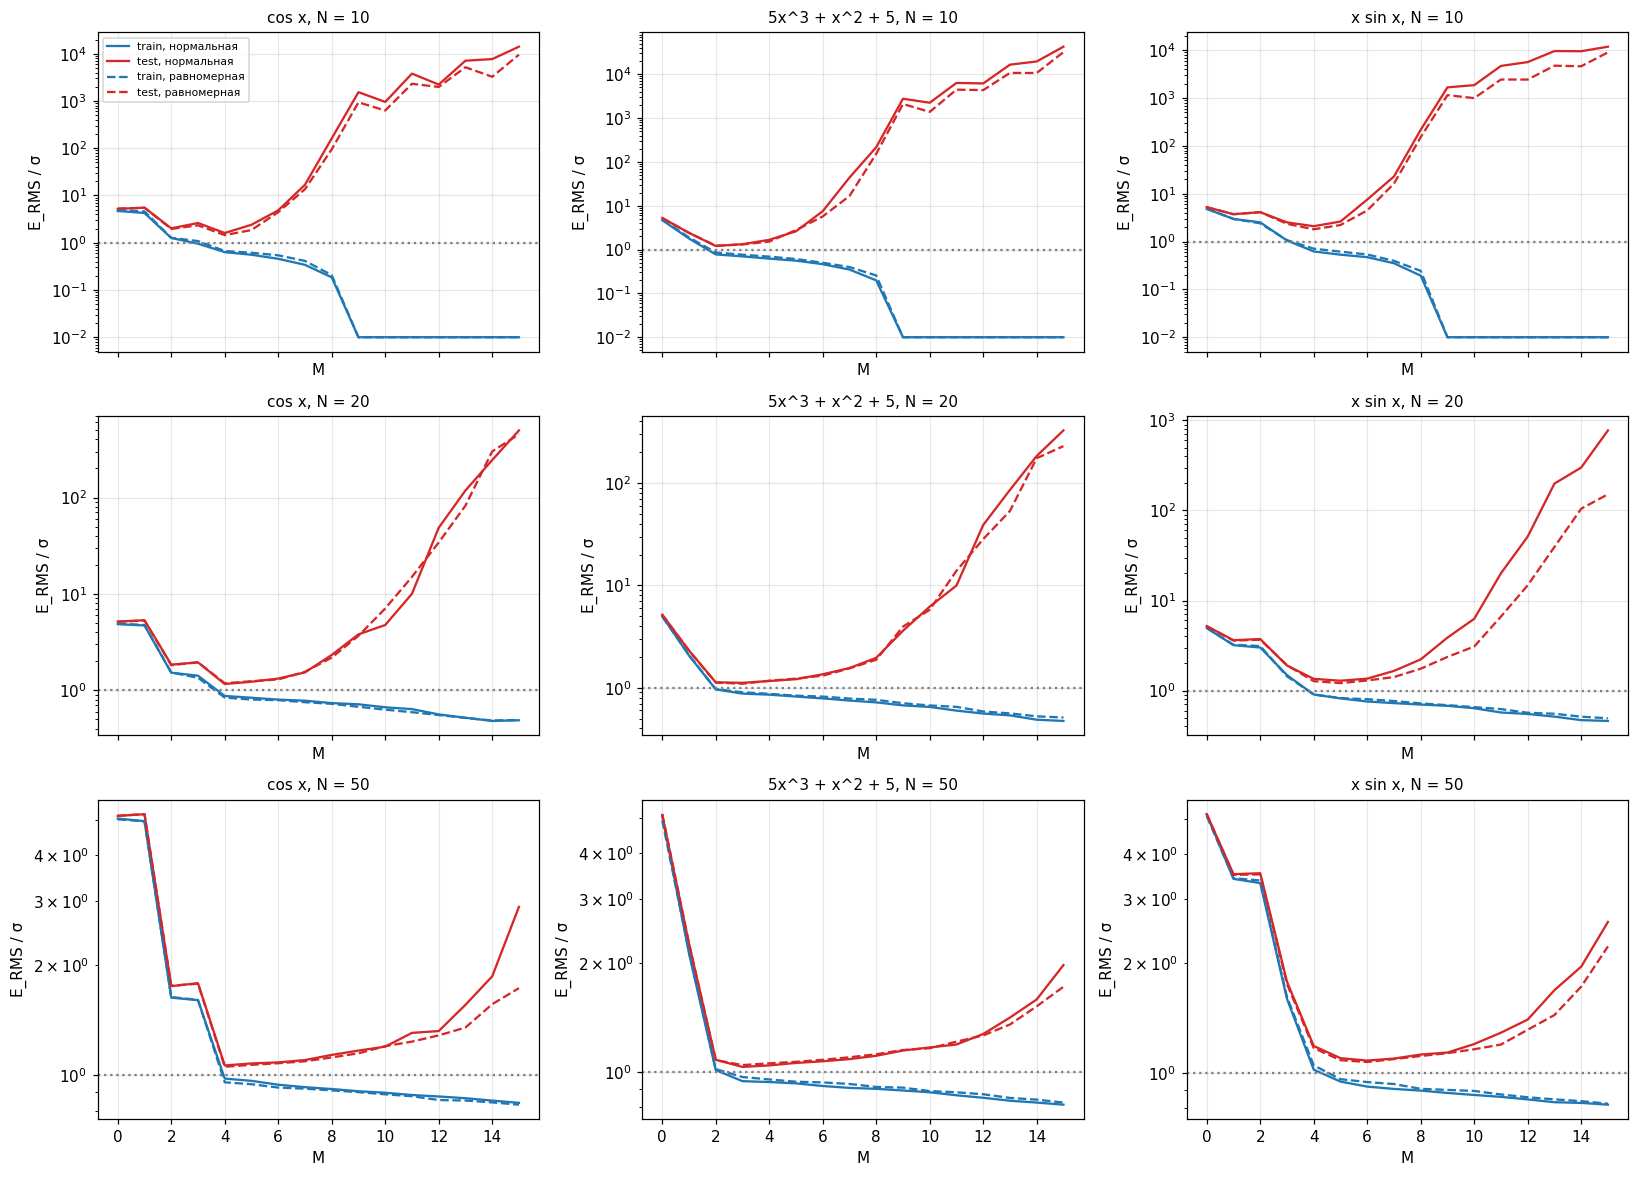

In [6]:
fig, axes = plt.subplots(len(N_VALUES), 3, figsize=(15, 3.6 * len(N_VALUES)), sharex=True)
for i, n in enumerate(N_VALUES):
    for j, func in enumerate(FUNCS):
        ax = axes[i, j]
        for noise_label, style in zip(NOISES, ["-", "--"]):
            s = res[(res["функция"] == func) & (res["ошибка"] == noise_label) & (res.N == n)]
            ax.semilogy(s.M, s.train.clip(lower=1e-2), "C0" + style, label=f"train, {noise_label}")
            ax.semilogy(s.M, s.test, "C3" + style, label=f"test, {noise_label}")
        ax.axhline(1, color="gray", ls=":")
        ax.set_title(f"{func}, N = {n}", fontsize=10)
        ax.set_xlabel("M"); ax.set_ylabel("E_RMS / σ")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [7]:
# Наилучшее M — минимум ошибки на контрольной выборке
best = res.loc[res.groupby(["функция", "ошибка", "N"])["test"].idxmin()]
print(best.pivot_table(index=["функция", "N"], columns="ошибка", values="M").astype(int))
print()
print(best.pivot_table(index=["функция", "N"], columns="ошибка", values="test").round(2))

ошибка             нормальная  равномерная
функция        N                          
5x^3 + x^2 + 5 10           2            2
               20           3            3
               50           3            3
cos x          10           4            4
               20           4            4
               50           4            4
x sin x        10           4            4
               20           5            5
               50           6            6

ошибка             нормальная  равномерная
функция        N                          
5x^3 + x^2 + 5 10        1.21         1.22
               20        1.12         1.09
               50        1.03         1.05
cos x          10        1.61         1.45
               20        1.16         1.19
               50        1.06         1.05
x sin x        10        2.10         1.81
               20        1.29         1.21
               50        1.08         1.07


In [8]:
# Ошибка на контрольной выборке при нескольких M (нормальная ошибка измерений)
s = res[res["ошибка"] == "нормальная"]
print(s[s.M.isin([3, 6, 9, 12, 15])].pivot_table(index=["функция", "M"], columns="N", values="test").round(2))

N                        10      20    50
функция        M                         
5x^3 + x^2 + 5 3       1.33    1.12  1.03
               6       7.51    1.35  1.07
               9    2762.31    3.60  1.15
               12   6169.79   38.90  1.27
               15  42505.80  326.62  1.97
cos x          3       2.62    1.95  1.79
               6       4.85    1.33  1.08
               9    1537.56    3.81  1.17
               12   2230.35   48.58  1.32
               15  14113.22  496.45  2.89
x sin x        3       2.52    1.90  1.78
               6       7.56    1.36  1.08
               9    1676.13    3.87  1.14
               12   5662.31   51.28  1.40
               15  11875.58  774.72  2.60


## 6. Выводы

* **Система (7) без нормализации решается неверно.** При $M = 15$ получается $E(w) = 104{,}6$
  вместо $18{,}9$. После Z-нормализации $x$ (13) результат верный при всех $M \le 15$.
* **Недообучение.** Полиномы степени $M \le 3$ не могут описать $\cos x$ и $x \sin x$: при $M = 3$
  ошибка на контрольной выборке равна $1{,}8\ldots2{,}6\,\sigma$.
* **Переобучение (п. 4.4).** Ошибка на обучающей выборке монотонно падает и при $M \ge N - 1$
  равна нулю (полином проходит через все точки), а на контрольной резко растёт. При $N = 10$ и
  $M = 9$ она в 1500–2800 раз больше $\sigma$, заметный рост начинается уже с $M \approx 6$.
* **Увеличение выборки устраняет переобучение.** При $M = 9$ ошибка падает с $1500\ldots2800\,\sigma$
  при $N = 10$ до $1{,}1\,\sigma$ при $N = 50$.
* **Наилучшая степень:** $M = 3$ для $5x^3 + x^2 + 5$ (при $N = 10$ — $M = 2$: четыре
  коэффициента по 10 точкам определяются плохо), $M = 4$ для $\cos x$, $M = 4\ldots6$ для
  $x \sin x$. С ростом $N$ наилучшее $M$ не убывает.
* **Закон распределения ошибки.** При одинаковом $\sigma$ нормальная и равномерная ошибки дают
  одинаковое наилучшее $M$ во всех 9 случаях и близкие значения ошибки. По п. 4.7 МНК обоснован
  как метод наибольшего правдоподобия только при нормальной ошибке, но на практике при
  равномерной работает так же хорошо.